## Análisis de datos II - Clase 8
---

### Auditoría de sesgos con Fairlearn y documentación automática con Model Cards
---

En esta notebook retomamos el escenario de aprobación de créditos de la notebook anterior (mismo dataset sintético y mismo modelo), pero con dos cambios:

1. Auditamos el sesgo con [Fairlearn](https://fairlearn.org/) en lugar de calcular las métricas a mano. MetricFrame nos da cualquier métrica desglosada por grupo en una sola línea.
2. Documentamos el modelo en forma automática con una Model Card generada con [skops](https://skops.readthedocs.io/), una biblioteca pensada para modelos de scikit-learn.

La idea central: los resultados de la auditoría no quedan "perdidos" en la notebook, sino que se escriben automáticamente en la documentación del modelo. Si reentrenamos, volvemos a correr la notebook y la Model Card se actualiza sola.

In [265]:
# %uv add "skops==0.16.0" tabulate fairlearn markdown
# conda install -c conda-forge "skops=0.16.0" tabulate fairlearn markdown

In [266]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
from sklearn.inspection import permutation_importance

from fairlearn.metrics import (
    MetricFrame,
    selection_rate,
    true_positive_rate,
    false_positive_rate,
    count,
    demographic_parity_difference,
    demographic_parity_ratio,
    equalized_odds_difference,
)

from skops import card

---
### Generación del dataset sintético (con sesgo)

Usamos exactamente el mismo código que en la notebook anterior: la variable protegida es el género (genero: 0 = grupo minoritario/mujeres, 1 = grupo mayoritario/hombres) y el grupo 0 recibe una penalización artificial en su puntaje crediticio.

In [267]:
np.random.seed(42)
n_muestras = 5000

# Variables simuladas
genero = np.random.binomial(1, 0.5, n_muestras) # 0 = Grupo minoritario, 1 = Grupo mayoritario
edad = np.random.randint(18, 70, n_muestras)
ingresos = np.random.normal(50000, 15000, n_muestras)
historial_crediticio = np.random.randint(0, 10, n_muestras)

# Inyectamos sesgo intencional. El género 0 recibe una penalización artificial fuerte en su puntaje
puntaje_base = (ingresos / 1000) * 0.5 + historial_crediticio * 2.5 - (edad * 0.03)
penalizacion_sesgo = np.where(genero == 0, 12, 0)
puntaje_final = puntaje_base - penalizacion_sesgo + np.random.normal(0, 2, n_muestras)

umbral = 35  # Umbral fijo
aprobado = (puntaje_final > umbral).astype(int)

df = pd.DataFrame({
    'edad': edad,
    'ingresos': ingresos,
    'historial_crediticio': historial_crediticio,
    'genero': genero, # Variable protegida
    'aprobado': aprobado
})

df.head()

,edad,ingresos,historial_crediticio,genero,aprobado
0,68,49800.007294,7,0,0
1,57,44859.401696,4,1,0
2,24,41005.045185,5,1,0
3,49,20539.517630,7,1,0
4,65,24006.895225,1,0,0


Recordemos que el sesgo ya está presente en los datos, antes de entrenar cualquier modelo:

In [268]:
pd.crosstab(df["genero"], df["aprobado"], normalize="index").rename(columns={0: "No aprobado", 1: "Aprobado"})

aprobado,No aprobado,Aprobado
genero,,
0,0.8660,0.1340
1,0.5284,0.4716


---
### Entrenamiento del modelo (Random Forest)

Mismo modelo que en la notebook anterior, incluyendo la variable genero.

In [269]:
X = df[['edad', 'ingresos', 'historial_crediticio', 'genero']]
y = df['aprobado']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

modelo = RandomForestClassifier(
    n_estimators=1000,
    max_depth=None,
    min_samples_split=2,
    random_state=0,
    n_jobs=-1
)

modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.96      0.97      0.97       724
           1       0.93      0.89      0.91       276

    accuracy                           0.95      1000
   macro avg       0.94      0.93      0.94      1000
weighted avg       0.95      0.95      0.95      1000



---
### Auditoría con Fairlearn

#### 1. MetricFrame: le puedo pasar cualquier métrica, desglosada por grupo

En la notebook anterior armamos un loop por grupo y una función para calcular TPR y FPR con la matriz de confusión. Con Fairlearn alcanza con indicar:
- las métricas que queremos (un diccionario nombre: función),
- los valores reales y las predicciones,
- atributos sensibles (sensitive_features).

In [270]:
A_test = X_test["genero"]  # atributo sensible

metricas = {
    "accuracy": accuracy_score,
    "precision": precision_score,
    "TPR (recall)": true_positive_rate,
    "FPR": false_positive_rate,
    "tasa de aprobación": selection_rate,
    "n": count,
}

mf = MetricFrame(
    metrics=metricas,
    y_true=y_test,
    y_pred=y_pred,
    sensitive_features=A_test,
)

mf.by_group

,accuracy,precision,TPR (recall),FPR,tasa de aprobación,n
genero,,,,,,
0,0.958095,0.915254,0.760563,0.011013,0.112381,525.0
1,0.943158,0.927885,0.941463,0.055556,0.437895,475.0


Son los mismos valores que calculamos a mano en la notebook anterior. Además, hay métodos que resumen las brechas entre grupos:
- difference(): diferencia entre el grupo con el valor más alto y el más bajo (0 = sin brecha).
- ratio(): cociente entre el valor más bajo y el más alto (1 = sin brecha).

In [271]:
pd.DataFrame({
    "global": mf.overall,
    "diferencia": mf.difference(),
    "ratio": mf.ratio(),
}).drop(index="n").round(3)

,global,diferencia,ratio
accuracy,0.951,0.015,0.984
precision,0.925,0.013,0.986
TPR (recall),0.895,0.181,0.808
FPR,0.028,0.045,0.198
tasa de aprobación,0.267,0.326,0.257


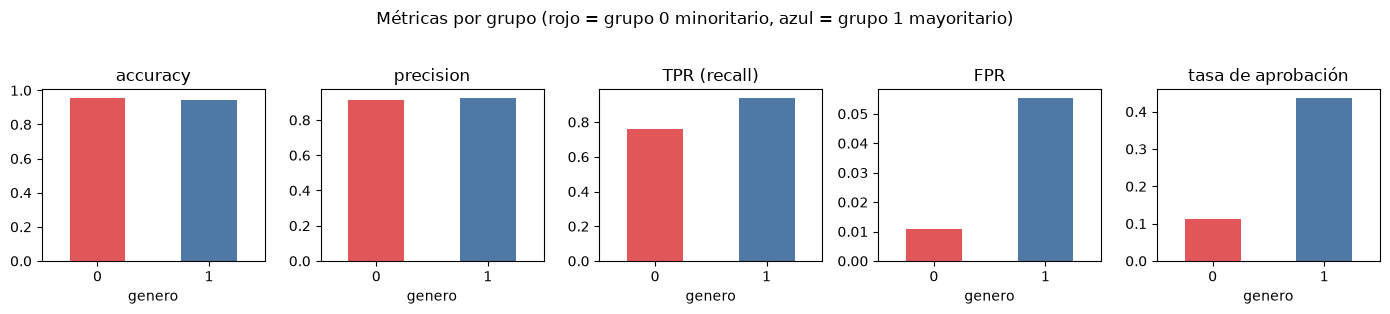

In [272]:
por_grupo = mf.by_group.drop(columns="n")

fig, axes = plt.subplots(1, len(por_grupo.columns), figsize=(14, 3))
for ax, metrica in zip(axes, por_grupo.columns):
    por_grupo[metrica].plot.bar(ax=ax, color=["#E15759", "#4E79A7"], rot=0, title=metrica)
    ax.set_xlabel("genero")
fig.suptitle("Métricas por grupo (rojo = grupo 0 minoritario, azul = grupo 1 mayoritario)", y=1.03)
plt.tight_layout()
plt.show()

#### 2. Demographic Parity y la regla del 80%

Fairlearn tiene funciones directas para las métricas de equidad más comunes:
- demographic_parity_difference: diferencia entre tasas de aprobación.
- demographic_parity_ratio: cociente entre tasas de aprobación. Es el Adverse Impact Ratio: si es menor a 0.8, no se cumple la regla del 80%.

In [273]:
dp_diff = demographic_parity_difference(y_test, y_pred, sensitive_features=A_test)
dp_ratio = demographic_parity_ratio(y_test, y_pred, sensitive_features=A_test)

print(f"Diferencia de Demographic Parity: {dp_diff:.3f}")
print(f"Ratio de Demographic Parity (AIR): {dp_ratio:.3f}")
print("Cumple la regla del 80%" if dp_ratio >= 0.8 else "NO cumple la regla del 80%")

Diferencia de Demographic Parity: 0.326
Ratio de Demographic Parity (AIR): 0.257
NO cumple la regla del 80%


#### 3. Equalized Odds

equalized_odds_difference devuelve la mayor de las dos brechas: la de TPR o la de FPR entre grupos. Si es 0, el modelo comete el mismo tipo de errores en ambos grupos.

In [274]:
eo_diff = equalized_odds_difference(y_test, y_pred, sensitive_features=A_test)
print(f"Diferencia de Equalized Odds: {eo_diff:.3f}")

Diferencia de Equalized Odds: 0.181


#### 4. Resumen de la auditoría

Armamos una tabla con los resultados y un "semáforo". Esta tabla es la que después va a ir a la Model Card.

Los umbrales son convenciones: 0.8 para el ratio (regla del 80%) y 0.1 para las diferencias pero cada organización puede definir los suyos y debe justificarlos.

In [275]:
UMBRAL_RATIO = 0.8
UMBRAL_DIFERENCIA = 0.1

def semaforo_ratio(valor):
    return "OK" if valor >= UMBRAL_RATIO else "ALERTA"

def semaforo_diferencia(valor):
    return "OK" if valor <= UMBRAL_DIFERENCIA else "ALERTA"

resumen_auditoria = pd.DataFrame([
    {"Métrica": "Demographic Parity (ratio / AIR)", "Valor": round(dp_ratio, 3),
     "Umbral": f">= {UMBRAL_RATIO}", "Resultado": semaforo_ratio(dp_ratio)},
    {"Métrica": "Demographic Parity (diferencia)", "Valor": round(dp_diff, 3),
     "Umbral": f"<= {UMBRAL_DIFERENCIA}", "Resultado": semaforo_diferencia(dp_diff)},
    {"Métrica": "Equalized Odds (diferencia)", "Valor": round(eo_diff, 3),
     "Umbral": f"<= {UMBRAL_DIFERENCIA}", "Resultado": semaforo_diferencia(eo_diff)},
])

resumen_auditoria

,Métrica,Valor,Umbral,Resultado
0,Demographic Parity (ratio / AIR),0.257,>= 0.8,ALERTA
1,Demographic Parity (diferencia),0.326,<= 0.1,ALERTA
2,Equalized Odds (diferencia),0.181,<= 0.1,ALERTA


#### Hallazgos

- La tasa de aprobación del grupo 0 es apenas una fracción de la del grupo 1: el ratio queda muy por debajo de 0.8.
- El modelo tampoco se equivoca igual en ambos grupos: con el grupo 0 tiene menor TPR (rechaza a más personas que sí habrían pagado).
- Igual que con SHAP, las métricas nos dicen que hay sesgo. Para entender por qué, combinamos con explicabilidad (notebook anterior).

---
### Experimento: ¿y si sacamos la variable genero?

Es la "solución" más intuitiva. Entrenemos el mismo modelo sin genero y auditemos de nuevo.

In [276]:
modelo_sin_genero = RandomForestClassifier(n_estimators=1000, random_state=0, n_jobs=-1)
modelo_sin_genero.fit(X_train.drop(columns="genero"), y_train)
y_pred_sin_genero = modelo_sin_genero.predict(X_test.drop(columns="genero"))

def auditar(y_pred_modelo):
    return {
        "accuracy": accuracy_score(y_test, y_pred_modelo),
        "DP ratio (AIR)": demographic_parity_ratio(y_test, y_pred_modelo, sensitive_features=A_test),
        "EO diferencia": equalized_odds_difference(y_test, y_pred_modelo, sensitive_features=A_test),
    }

comparacion = pd.DataFrame({
    "Con genero": auditar(y_pred),
    "Sin genero": auditar(y_pred_sin_genero),
}).round(3)

comparacion

,Con genero,Sin genero
accuracy,0.951,0.811
DP ratio (AIR),0.257,0.886
EO diferencia,0.181,0.297


In [277]:
MetricFrame(
    metrics={"TPR (recall)": true_positive_rate, "FPR": false_positive_rate, "tasa de aprobación": selection_rate},
    y_true=y_test, y_pred=y_pred_sin_genero, sensitive_features=A_test
).by_group

,TPR (recall),FPR,tasa de aprobación
genero,,,
0,0.887324,0.204846,0.297143
1,0.590244,0.014815,0.263158


#### ¿Qué pasó?

- Demographic Parity mejora mucho: en este dataset genero no está correlacionado con las otras variables (no hay proxies), así que sin ella el modelo aprueba en proporciones similares a ambos grupos.
- Sin embargo, Equalized Odds empeora y la accuracy cae: las etiquetas (aprobado) siguen siendo las históricas, que ya venían sesgadas. El modelo ahora "se equivoca" contra esas etiquetas de forma distinta en cada grupo.

Conclusiones:
1. No hay una métrica "correcta": mejorar una puede empeorar otra. Elegir cuál priorizar es una decisión, y hay que documentarla.
2. Si las etiquetas están sesgadas, las métricas que las usan (accuracy, TPR, FPR) también lo están.
3. En datos reales, sacar la variable sensible no suele alcanzar, porque el modelo la reconstruye a partir de proxies.

---
### Documentación automática: Model Card con skops


Vamos a armar una Model Card con las siguientes secciones:

1. Detalles del modelo
2. Uso previsto y usos fuera de alcance ("No usar para…")
3. Datos
4. Métricas de desempeño
5. Auditoría de sesgos
6. Explicabilidad
7. Limitaciones y riesgos
8. Monitoreo

Ventaja: todo lo que sale de la notebook (métricas, auditoría, gráficos) se escribe automáticamente.

#### 1. Creamos la carpeta y la card vacía

- template=None nos deja definir nuestras propias secciones (la plantilla por defecto de skops está en inglés).
- model_diagram=False evita incluir el diagrama HTML del modelo, que no aporta mucho para un Random Forest.

In [278]:
carpeta_card = Path("model_card")
carpeta_card.mkdir(exist_ok=True)

mc = card.Card(modelo, template=None, model_diagram=False)

#### 2. Secciones de texto

Algunas secciones las escribe una persona (uso previsto, usos fuera de alcance), pero incluso ahí podemos completar datos automáticamente con f-strings.

Las secciones anidadas se crean con "/": por ejemplo "Uso previsto/No usar para".

In [ ]:
mc.add(**{
    "Detalles del modelo": (
        f"- **Nombre:** Modelo de aprobación de créditos (ejemplo de clase)\n"
        f"- **Versión:** 1.0\n"
        f"- **Fecha:** {pd.Timestamp.today():%d/%m/%Y}\n"
        f"- **Tipo de modelo:** {type(modelo).__name__} ({modelo.n_estimators} árboles)\n"
        f"- **Responsable:** equipo clase AndDII\n"
        f"- **Variables de entrada:** {', '.join(X.columns)}\n"
        f"- **Variable objetivo:** aprobado (1 = crédito aprobado)"
    ),
    "Uso previsto": (
        "Modelo para aprender y para practicar auditoría de sesgos y documentación. "
        "Predice si una solicitud de crédito sería aprobada según el criterio histórico del banco."
    ),
    "NO previsto para": (
        "- Tomar decisiones reales de crédito: los datos son sintéticos.\n"
        "- Usarse como única fuente para rechazar una solicitud.\n"
        "- Aplicarlo a poblaciones con características distintas a las de entrenamiento "
        f"(edades fuera del rango {X['edad'].min()}-{X['edad'].max()} años)."
    ),
})

Card(
  model=RandomForestClassifier(n_estimators=1000, n_jobs=-1, random_state=0),
  Detalles del modelo=- **Nombre:** Modelo de apr...obado (1 = crédito aprobado),
  Uso previsto=Modelo para aprender y para pra...l criterio histórico del banco.,
  NO previsto para=- Tomar decisiones reales de ... fuera del rango 18-69 años).,
)

#### 3. Datos (generados automáticamente)

Describimos el dataset con estadísticas calculadas en el momento y las agregamos a la Data Card.

In [280]:
tasa_aprob_datos = df.groupby("genero")["aprobado"].mean()

mc.add(**{
    "Datos": (
        f"- **Origen:** dataset sintético generado en la notebook (semilla 42).\n"
        f"- **Tamaño:** {len(df)} registros; {len(X_train)} para entrenamiento y {len(X_test)} para test.\n"
        f"- **Atributo sensible:** `genero` ({(df['genero'] == 0).mean():.0%} grupo 0, {(df['genero'] == 1).mean():.0%} grupo 1).\n"
        f"- **Sesgo histórico en las etiquetas:** la tasa de aprobación en los datos es {tasa_aprob_datos[0]:.1%} "
        f"para el grupo 0 y {tasa_aprob_datos[1]:.1%} para el grupo 1. "
        "El sesgo está presente antes de entrenar el modelo."
    )
})

Card(
  model=RandomForestClassifier(n_estimators=1000, n_jobs=-1, random_state=0),
  Detalles del modelo=- **Nombre:** Modelo de apr...obado (1 = crédito aprobado),
  Uso previsto=Modelo para aprender y para pra...l criterio histórico del banco.,
  NO previsto para=- Tomar decisiones reales de ... fuera del rango 18-69 años).,
  Datos=- **Origen:** dataset sintético ge...esente antes de entrenar el modelo.,
)

#### 4. Métricas de desempeño (automático)

add_metrics arma la tabla a partir de los valores que le pasamos.

In [281]:
mc.add_metrics(
    section="Métricas de desempeño",
    description="Métricas calculadas sobre el conjunto de test.",
    accuracy=round(accuracy_score(y_test, y_pred), 3),
    precision=round(precision_score(y_test, y_pred), 3),
    recall=round(recall_score(y_test, y_pred), 3),
    f1=round(f1_score(y_test, y_pred), 3),
)

Card(
  model=RandomForestClassifier(n_estimators=1000, n_jobs=-1, random_state=0),
  Detalles del modelo=- **Nombre:** Modelo de apr...obado (1 = crédito aprobado),
  Uso previsto=Modelo para aprender y para pra...l criterio histórico del banco.,
  NO previsto para=- Tomar decisiones reales de ... fuera del rango 18-69 años).,
  Datos=- **Origen:** dataset sintético ge...esente antes de entrenar el modelo.,
  Métricas de desempeño=TableSection(4x2),
)

#### 5. Auditoría de sesgos (automático)

Agregamos:
- el resumen con el semáforo,
- las métricas desglosadas por grupo (mf.by_group),
- un gráfico,
- una conclusión que **se escribe sola** según los resultados.

Las tablas las convertimos a Markdown con DataFrame.to_markdown(). skops también tiene add_table (recibe un DataFrame) y add_fairlearn_metric_frame (recibe un MetricFrame directamente), pero la primera no permite anidar la tabla dentro de una sección y la segunda no muestra los nombres de las filas, así que las armamos nosotros.

In [282]:
# Gráfico de tasa de aprobación y TPR por grupo, guardado dentro de la carpeta de la card
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
for ax, metrica in zip(axes, ["tasa de aprobación", "TPR (recall)"]):
    mf.by_group[metrica].plot.bar(ax=ax, color=["#E15759", "#4E79A7"], rot=0, title=metrica)
    ax.set_xlabel("genero")
plt.tight_layout()
fig.savefig(carpeta_card / "auditoria_por_grupo.png", dpi=120)
plt.close(fig)

# Conclusión automática según los resultados
alertas = resumen_auditoria.loc[resumen_auditoria["Resultado"] == "ALERTA", "Métrica"].tolist()
if alertas:
    conclusion = (
        f"**Se detectaron disparidades** en: {', '.join(alertas)}. "
        f"El ratio de aprobación (AIR) es {dp_ratio:.2f}, por debajo de la regla del 80%. "
        "El modelo no está apto para producción sin un plan de mitigación."
    )
else:
    conclusion = "No se detectaron disparidades por encima de los umbrales definidos."

mc.add(**{
    "Auditoría de sesgos": (
        f"Auditoría realizada con Fairlearn sobre el conjunto de test, usando `genero` como atributo sensible. "
        f"Umbrales: ratio >= {UMBRAL_RATIO} (regla del 80%) y diferencias <= {UMBRAL_DIFERENCIA}."
    ),
    "Auditoría de sesgos/Conclusión": conclusion,
})

# Las tablas se agregan como texto Markdown (to_markdown) para poder anidarlas dentro de la sección
tabla_por_grupo = mf.by_group.round(3).astype({"n": int}).reset_index()

mc.add(**{
    "Auditoría de sesgos/Resumen": resumen_auditoria.to_markdown(index=False),
    "Auditoría de sesgos/Métricas por grupo": tabla_por_grupo.to_markdown(index=False),
})

mc.add_plot(**{"Auditoría de sesgos/Gráfico": "auditoria_por_grupo.png"})

Card(
  model=RandomForestClassifier(n_estimators=1000, n_jobs=-1, random_state=0),
  Detalles del modelo=- **Nombre:** Modelo de apr...obado (1 = crédito aprobado),
  Uso previsto=Modelo para aprender y para pra...l criterio histórico del banco.,
  NO previsto para=- Tomar decisiones reales de ... fuera del rango 18-69 años).,
  Datos=- **Origen:** dataset sintético ge...esente antes de entrenar el modelo.,
  Métricas de desempeño=TableSection(4x2),
  Auditoría de sesgos=Auditoría realizada con Fai...l 80%) y diferencias <= 0.1.,
  Auditoría de sesgos/Conclusión=**Se detectaron dispar...un plan de mitigación.,
  Auditoría de sesgos/Resumen=| Métrica | Valor | Umb....181 | <= 0.1 | ALERTA |,
  Auditoría de sesgos/Métricas por grupo=| genero | accurac...56 | 0.438 | 475 |,
  Auditoría de sesgos/Gráfico=PlotSection(auditoria_por_grupo.png),
)

#### 6. Explicabilidad (automático)

Usamos importancia por permutación que viene en scikit-learn. También se podría reemplazar este gráfico por el summary plot de SHAP que vimos en la notebook de sesgos.

In [283]:
pi = permutation_importance(modelo, X_test, y_test, n_repeats=10, random_state=0, n_jobs=-1)
importancias = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()

fig, ax = plt.subplots(figsize=(6, 3))
importancias.plot.barh(ax=ax, color="#4E79A7")
ax.set_title("Importancia por permutación (test)")
ax.set_xlabel("Caída en accuracy al permutar la variable")
plt.tight_layout()
fig.savefig(carpeta_card / "importancia_permutacion.png", dpi=120)
plt.close(fig)

posicion_genero = list(importancias.sort_values(ascending=False).index).index("genero") + 1

mc.add(**{
    "Explicabilidad": (
        f"La variable sensible `genero` ocupa el puesto {posicion_genero} de {len(importancias)} "
        "en importancia: el modelo la usa directamente para decidir."
    )
})
mc.add_plot(**{"Explicabilidad/Importancia por permutación": "importancia_permutacion.png"})

Card(
  model=RandomForestClassifier(n_estimators=1000, n_jobs=-1, random_state=0),
  Detalles del modelo=- **Nombre:** Modelo de apr...obado (1 = crédito aprobado),
  Uso previsto=Modelo para aprender y para pra...l criterio histórico del banco.,
  NO previsto para=- Tomar decisiones reales de ... fuera del rango 18-69 años).,
  Datos=- **Origen:** dataset sintético ge...esente antes de entrenar el modelo.,
  Métricas de desempeño=TableSection(4x2),
  Auditoría de sesgos=Auditoría realizada con Fai...l 80%) y diferencias <= 0.1.,
  Auditoría de sesgos/Conclusión=**Se detectaron dispar...un plan de mitigación.,
  Auditoría de sesgos/Resumen=| Métrica | Valor | Umb....181 | <= 0.1 | ALERTA |,
  Auditoría de sesgos/Métricas por grupo=| genero | accurac...56 | 0.438 | 475 |,
  Auditoría de sesgos/Gráfico=PlotSection(auditoria_por_grupo.png),
  Explicabilidad=La variable sensible `genero` ...usa directamente para decidir.,
  Explicabilidad/Importancia por permutación=PlotSection(impo...per

#### 7. Limitaciones, riesgos y monitoreo

Documentamos también el experimento de sacar la variable genero, con los números calculados.

In [284]:
mc.add(**{
    "Limitaciones y riesgos": (
        "- **Etiquetas sesgadas:** el modelo aprende de decisiones históricas que ya penalizaban al grupo 0.\n"
        f"- **Quitar `genero` no resuelve el problema:** sin la variable, el AIR sube a "
        f"{comparacion.loc['DP ratio (AIR)', 'Sin genero']:.2f}, pero la diferencia de Equalized Odds pasa de "
        f"{comparacion.loc['EO diferencia', 'Con genero']:.2f} a {comparacion.loc['EO diferencia', 'Sin genero']:.2f} "
        f"y la accuracy cae de {comparacion.loc['accuracy', 'Con genero']:.2f} a {comparacion.loc['accuracy', 'Sin genero']:.2f}.\n"
        "- **Datos sintéticos:** no hay proxies del género; en datos reales el sesgo podría persistir aun sin la variable.\n"
        "- **Elección de métrica:** se priorizó Demographic Parity (regla del 80%); la decisión debe validarse con el área de negocio y legal."
    ),
    "Monitoreo": (
        "- Recalcular esta auditoría con cada reentrenamiento y mensualmente en producción.\n"
        "- Monitorear drift de `ingresos` e `historial_crediticio` con PSI (alerta si PSI > 0.25).\n"
        "- Revisar el desempeño por grupo cuando lleguen las etiquetas reales (pagó / no pagó)."
    ),
})

mc.add_hyperparams(section="Anexo: hiperparámetros", description="Hiperparámetros del modelo entrenado.")

Card(
  model=RandomForestClassifier(n_estimators=1000, n_jobs=-1, random_state=0),
  Detalles del modelo=- **Nombre:** Modelo de apr...obado (1 = crédito aprobado),
  Uso previsto=Modelo para aprender y para pra...l criterio histórico del banco.,
  NO previsto para=- Tomar decisiones reales de ... fuera del rango 18-69 años).,
  Datos=- **Origen:** dataset sintético ge...esente antes de entrenar el modelo.,
  Métricas de desempeño=TableSection(4x2),
  Auditoría de sesgos=Auditoría realizada con Fai...l 80%) y diferencias <= 0.1.,
  Auditoría de sesgos/Conclusión=**Se detectaron dispar...un plan de mitigación.,
  Auditoría de sesgos/Resumen=| Métrica | Valor | Umb....181 | <= 0.1 | ALERTA |,
  Auditoría de sesgos/Métricas por grupo=| genero | accurac...56 | 0.438 | 475 |,
  Auditoría de sesgos/Gráfico=PlotSection(auditoria_por_grupo.png),
  Explicabilidad=La variable sensible `genero` ...usa directamente para decidir.,
  Explicabilidad/Importancia por permutación=PlotSection(impo...per

#### 8. Guardamos la Model Card

get_toc() muestra la estructura y save() escribe el archivo README.md.

In [285]:
print(mc.get_toc())

- Detalles del modelo
- Uso previsto
- NO previsto para
- Datos
- Métricas de desempeño
- Auditoría de sesgos
  - Conclusión
  - Resumen
  - Métricas por grupo
  - Gráfico
- Explicabilidad
  - Importancia por permutación
- Limitaciones y riesgos
- Monitoreo
- Anexo: hiperparámetros


In [286]:
mc.save(carpeta_card / "README.md")
print("Model Card guardada en:", carpeta_card / "README.md")

Model Card guardada en: model_card/README.md


#### 9. Exportamos a HTML y la abrimos en el browser

Convertimos el Markdown a HTML para poder visualizarla en el browser. Las imágenes quedan en la misma carpeta, así que hay que compartir la carpeta completa.

Nota: abrir el navegador funciona si Jupyter corre en tu computadora (Jupyter local o VS Code). En Google Colab hay que descargar la carpeta model_card y abrir el HTML a mano.

In [287]:
import markdown
import webbrowser

In [288]:

texto_card = (carpeta_card / "README.md").read_text(encoding="utf-8")

# skops guarda los hiperparámetros dentro de un bloque desplegable (<details>).
# markdown="1" + la extensión md_in_html hacen que la tabla de adentro también se convierta.
texto_card = (
    texto_card
    .replace("<details>", '<details markdown="1">')
    .replace("Click to expand", "Ver hiperparámetros")
)
html_body = markdown.markdown(texto_card, extensions=["tables", "md_in_html"])
html = f"""<!doctype html>
<html lang="es"><head><meta charset="utf-8"><title>Model Card</title>
<style>
body {{ font-family: sans-serif; max-width: 900px; margin: 2rem auto; padding: 0 1rem; line-height: 1.5; }}
table {{ border-collapse: collapse; margin: 1rem 0; }}
th, td {{ border: 1px solid #ccc; padding: 4px 10px; text-align: center; }}
th {{ background: #f0f0f8; }}
img {{ max-width: 100%; }}
summary {{ cursor: pointer; font-weight: bold; }}
</style></head><body>{html_body}</body></html>"""

ruta_html = (carpeta_card / "model_card.html").resolve()
ruta_html.write_text(html, encoding="utf-8")

webbrowser.open(ruta_html.as_uri())

True

---
### Notas finales

- Fairlearn simplifica la auditoría: MetricFrame calcula cualquier métrica por grupo y tiene funciones directas para Demographic Parity y Equalized Odds.
- skops permite que la documentación se genere desde el mismo código que entrena y audita el modelo: si el modelo cambia, la Model Card cambia con él.
- La parte que no se automatiza (uso previsto, "No usar para…", elección de métricas) es la más importante, y sigue siendo responsabilidad del equipo desarollador.